In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_excel(r"C:\Users\hp\Desktop\healthcare-mlops\data\raw\healthcare_data_acuity_bundle.xlsx")

In [5]:
df.shape

(20160, 52)

In [6]:
df.head()

,Patient_ID,Name,Age,Gender,Department,Diagnosis,ICU_Admitted,Assigned_Doctor,Assigned_Nurse,Blood_Type,...,Mortality,Admission_Date,Gender_Enc,ICU_Admitted_Enc,ICU_Transfer_Enc,Readmission_Enc,Age_Bucket,Dept_Enc,Diag_Enc,Acuity_Bundle_Enc
0,100001,Patient_00000,24.0,F,Ward,Trauma,No,Dr_11,Nurse_57,B+,...,No,2024-02-06 00:00:00,1,0,0,1,18-30,0,7,0
1,100002,Patient_00001,74.0,F,ICU,Fever,Yes,Dr_20,Nurse_8,O+,...,No,2025-01-03 00:00:00,1,1,1,0,61-75,2,1,3
2,100003,Patient_00002,65.0,M,ER,Respiratory,Yes,Dr_2,Nurse_32,O+,...,No,2024-03-15 00:00:00,0,1,1,0,61-75,1,4,3
3,100004,Patient_00003,50.0,M,Ward,Stroke,No,Dr_20,Nurse_14,A-,...,No,2025-10-01 00:00:00,0,0,0,0,46-60,0,6,0
4,100005,Patient_00004,49.0,M,Ward,Cardiac,No,Dr_16,Nurse_14,O+,...,No,2025-06-15 00:00:00,0,0,0,0,46-60,0,0,1


In [7]:
df.columns

Index(['Patient_ID', 'Name', 'Age', 'Gender', 'Department', 'Diagnosis',
       'ICU_Admitted', 'Assigned_Doctor', 'Assigned_Nurse', 'Blood_Type',
       'Comorbidities', 'Insurance', 'Mean_HR', 'Max_HR', 'Std_HR',
       'Mean_SpO2', 'Min_SpO2', 'Mean_BP_Sys', 'Min_BP_Sys', 'Max_Temp',
       'Mean_RR', 'Max_RR', 'Mean_GCS', 'Min_GCS', 'Hypoxia_Episodes',
       'Tachycardia_Episodes', 'Vitals_Count', 'Acuity_Level', 'Risk_Score',
       'NEWS2', 'qSOFA', 'SIRS', 'Acuity_Bundle', 'Bundle_Compliance',
       'Avg_Bundle_Delay', 'Total_Bundle_Steps', 'LOS', 'Status',
       'Discharge_Status', 'ICU_Transfer', 'Readmission', 'Total_Cost_USD',
       'Mortality', 'Admission_Date', 'Gender_Enc', 'ICU_Admitted_Enc',
       'ICU_Transfer_Enc', 'Readmission_Enc', 'Age_Bucket', 'Dept_Enc',
       'Diag_Enc', 'Acuity_Bundle_Enc'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20160 entries, 0 to 20159
Data columns (total 52 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Patient_ID            20160 non-null  int64  
 1   Name                  20160 non-null  str    
 2   Age                   19980 non-null  float64
 3   Gender                20038 non-null  str    
 4   Department            19938 non-null  str    
 5   Diagnosis             19908 non-null  str    
 6   ICU_Admitted          20160 non-null  str    
 7   Assigned_Doctor       20160 non-null  str    
 8   Assigned_Nurse        20160 non-null  str    
 9   Blood_Type            20160 non-null  str    
 10  Comorbidities         19843 non-null  str    
 11  Insurance             19805 non-null  str    
 12  Mean_HR               19656 non-null  float64
 13  Max_HR                20160 non-null  float64
 14  Std_HR                20160 non-null  float64
 15  Mean_SpO2             19705 no

In [10]:
print("Numerical columns:")
print(df.select_dtypes(include=["int64", "float64"]).columns)

print("\nCategorical columns:")
print(df.select_dtypes(include=["object"]).columns)

Numerical columns:
Index(['Patient_ID', 'Age', 'Mean_HR', 'Max_HR', 'Std_HR', 'Mean_SpO2',
       'Min_SpO2', 'Mean_BP_Sys', 'Min_BP_Sys', 'Max_Temp', 'Mean_RR',
       'Max_RR', 'Mean_GCS', 'Min_GCS', 'Hypoxia_Episodes',
       'Tachycardia_Episodes', 'Vitals_Count', 'Risk_Score', 'NEWS2', 'qSOFA',
       'SIRS', 'Bundle_Compliance', 'Avg_Bundle_Delay', 'Total_Bundle_Steps',
       'LOS', 'Total_Cost_USD', 'Gender_Enc', 'ICU_Admitted_Enc',
       'ICU_Transfer_Enc', 'Readmission_Enc', 'Dept_Enc', 'Diag_Enc',
       'Acuity_Bundle_Enc'],
      dtype='str')

Categorical columns:
Index(['Name', 'Gender', 'Department', 'Diagnosis', 'ICU_Admitted',
       'Assigned_Doctor', 'Assigned_Nurse', 'Blood_Type', 'Comorbidities',
       'Insurance', 'Acuity_Level', 'Acuity_Bundle', 'Status',
       'Discharge_Status', 'ICU_Transfer', 'Readmission', 'Mortality',
       'Admission_Date', 'Age_Bucket'],
      dtype='str')


C:\Users\hp\AppData\Local\Temp\ipykernel_11732\2368647023.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include=["object"]).columns)


In [12]:
df.isnull().sum()

Patient_ID                0
Name                      0
Age                     180
Gender                  122
Department              222
Diagnosis               252
ICU_Admitted              0
Assigned_Doctor           0
Assigned_Nurse            0
Blood_Type                0
Comorbidities           317
Insurance               355
Mean_HR                 504
Max_HR                    0
Std_HR                    0
Mean_SpO2               455
Min_SpO2                  0
Mean_BP_Sys             403
Min_BP_Sys                0
Max_Temp                353
Mean_RR                 302
Max_RR                    0
Mean_GCS                252
Min_GCS                   0
Hypoxia_Episodes          0
Tachycardia_Episodes      0
Vitals_Count              0
Acuity_Level              0
Risk_Score              300
NEWS2                     0
qSOFA                     0
SIRS                      0
Acuity_Bundle             0
Bundle_Compliance         0
Avg_Bundle_Delay          0
Total_Bundle_Steps  

In [13]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)

print(missing_percent.round(2))

Mean_HR           2.50
Mean_SpO2         2.26
Mean_BP_Sys       2.00
Insurance         1.76
Max_Temp          1.75
Comorbidities     1.57
Mean_RR           1.50
Risk_Score        1.49
Mean_GCS          1.25
Diagnosis         1.25
Department        1.10
Age               0.89
Gender            0.61
Admission_Date    0.04
dtype: float64


In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 156


In [15]:
print("Duplicate Patient IDs:", df["Patient_ID"].duplicated().sum())

Duplicate Patient IDs: 160


In [16]:
df[df["Patient_ID"].duplicated(keep=False)].head(10)

,Patient_ID,Name,Age,Gender,Department,Diagnosis,ICU_Admitted,Assigned_Doctor,Assigned_Nurse,Blood_Type,...,Mortality,Admission_Date,Gender_Enc,ICU_Admitted_Enc,ICU_Transfer_Enc,Readmission_Enc,Age_Bucket,Dept_Enc,Diag_Enc,Acuity_Bundle_Enc
44,100045,Patient_00044,22.0,M,Ward,Cardiac,No,Dr_19,Nurse_31,A-,...,No,2024-10-06 00:00:00,0,0,0,0,18-30,0,0,0
179,100180,Patient_00179,54.0,F,Ward,Sepsis,No,Dr_2,Nurse_19,O-,...,No,2024-08-27 00:00:00,1,0,0,0,46-60,0,5,0
300,100301,Patient_00300,44.0,M,ER,Fever,Yes,Dr_20,Nurse_11,B+,...,No,2024-03-16 00:00:00,0,1,1,1,31-45,1,1,4
421,100422,Patient_00421,68.0,M,ER,Pneumonia,Yes,Dr_2,Nurse_58,B+,...,No,2024-10-27 00:00:00,0,1,0,1,61-75,1,3,3
429,100430,Patient_00429,70.0,F,ICU,Respiratory,Yes,Dr_4,Nurse_56,AB+,...,No,2025-04-06 00:00:00,1,1,1,0,61-75,2,4,4
570,100571,Patient_00570,87.0,F,ER,Respiratory,Yes,Dr_14,Nurse_31,A+,...,No,2025-10-13 00:00:00,1,1,0,0,76+,1,4,3
689,100690,Patient_00689,75.0,F,ER,Respiratory,No,Dr_7,Nurse_32,B-,...,No,2025-11-21 00:00:00,1,0,0,0,61-75,1,4,1
701,100702,Patient_00701,62.0,M,ICU,Respiratory,Yes,Dr_7,Nurse_26,O-,...,No,2025-06-12 00:00:00,0,1,1,0,61-75,2,4,4
709,100710,Patient_00709,52.0,F,Ward,Fever,No,Dr_7,Nurse_19,A+,...,No,2025-11-12 00:00:00,1,0,1,0,46-60,0,1,2
1016,101017,Patient_01016,46.0,M,Ward,Sepsis,Yes,Dr_11,Nurse_1,B+,...,No,2024-08-24 00:00:00,0,1,0,0,46-60,0,5,3


In [17]:
categorical_columns = [
    "Gender",
    "Department",
    "Insurance",
    "Comorbidities"
]

for col in categorical_columns:
    print("\nColumn:", col)
    print(df[col].value_counts(dropna=False))


Column: Gender
Gender
M           10985
F            8963
NaN           122
f              15
m              15
 male          15
Male           15
 female        15
Female         15
Name: count, dtype: int64

Column: Department
Department
Ward         7240
ICU          6553
ER           6010
NaN           222
WARD           23
icu            23
 Icu           22
 ward          22
Emergency      15
emergency      15
 er            15
Name: count, dtype: int64

Column: Insurance
Insurance
Government     10653
Private         7279
Self-Pay        1738
NaN              355
private           23
Self Pay          23
PRIV              22
self-pay          22
Govt              15
government        15
GOVERNMENT        15
Name: count, dtype: int64

Column: Comorbidities
Comorbidities
Diabetes           3386
CKD                3346
COPD               3310
Hypertension       3282
Both               3279
No_Comorbidity     3210
NaN                 317
NO_COMORBIDITY       15
No comorbidity     

In [18]:
numerical_columns = [
    "Age",
    "Mean_HR",
    "Mean_SpO2",
    "Mean_BP_Sys",
    "Max_Temp",
    "Mean_RR",
    "Mean_GCS"
]

print(df[numerical_columns].describe().T)

               count        mean        std   min    25%    50%    75%    max
Age          19980.0   53.809409  22.119866  -5.0   36.0   54.0   72.0  999.0
Mean_HR      19656.0   85.650046  12.880004 -20.0   77.1   85.6   94.0  450.0
Mean_SpO2    19705.0   95.583431   2.408069   5.0   94.3   95.6   96.9  250.0
Mean_BP_Sys  19757.0  115.654695  14.889023 -30.0  105.9  115.6  125.4  550.0
Max_Temp     19807.0   37.284056   0.914661   5.0   36.9   37.3   37.7  120.0
Mean_RR      19858.0   19.196102   4.051541  -3.0   16.7   19.2   21.6  200.0
Mean_GCS     19908.0   14.365612   0.718034  -2.0   13.9   14.5   15.0   50.0


In [19]:
quality_summary = pd.DataFrame({
    "Data_Type": df.dtypes,
    "Missing_Values": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100,
    "Unique_Values": df.nunique()
})

quality_summary

,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
Patient_ID,int64,0,0.000000,20000
Name,str,0,0.000000,20000
Age,float64,180,0.892857,78
Gender,str,122,0.605159,8
Department,str,222,1.101190,10
Diagnosis,str,252,1.250000,8
ICU_Admitted,str,0,0.000000,2
Assigned_Doctor,str,0,0.000000,20
Assigned_Nurse,str,0,0.000000,60
Blood_Type,str,0,0.000000,8


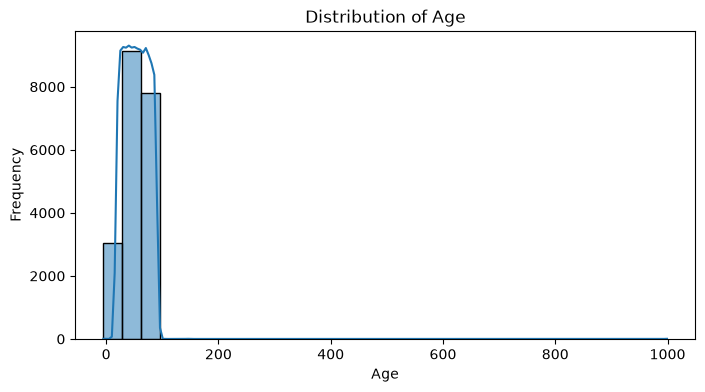

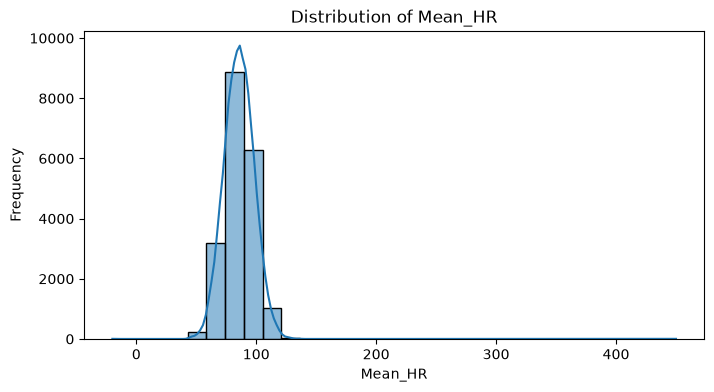

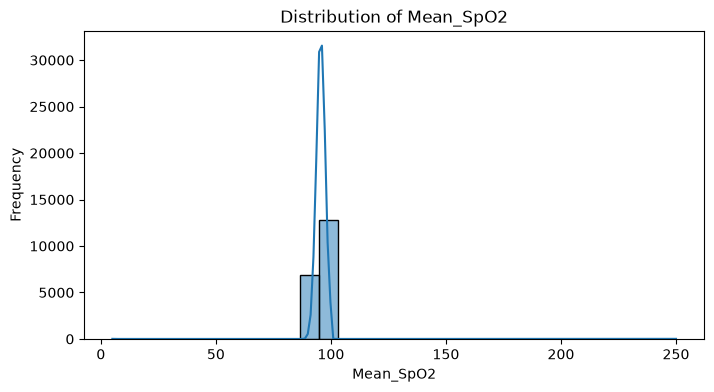

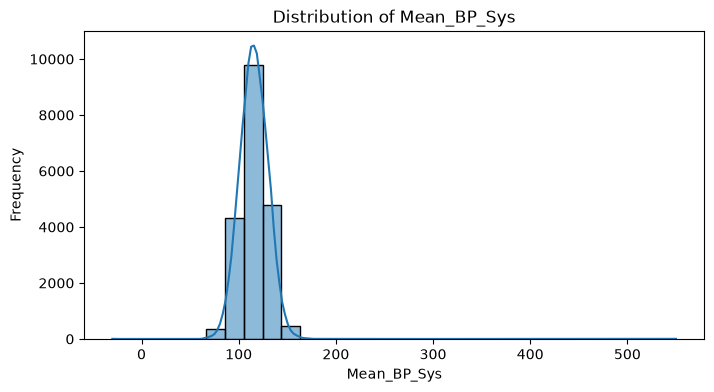

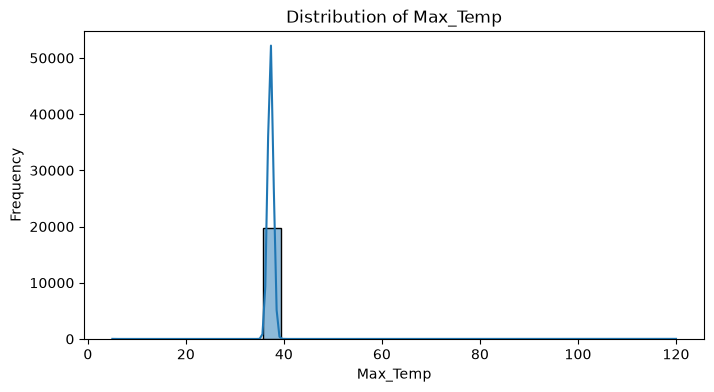

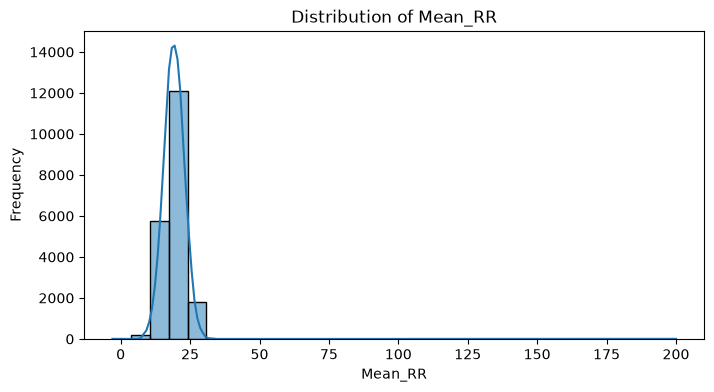

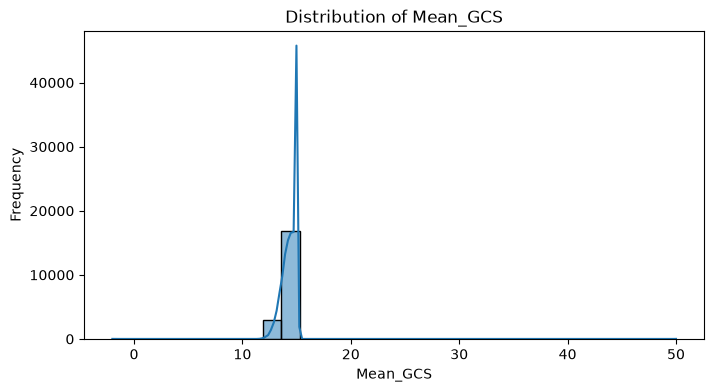

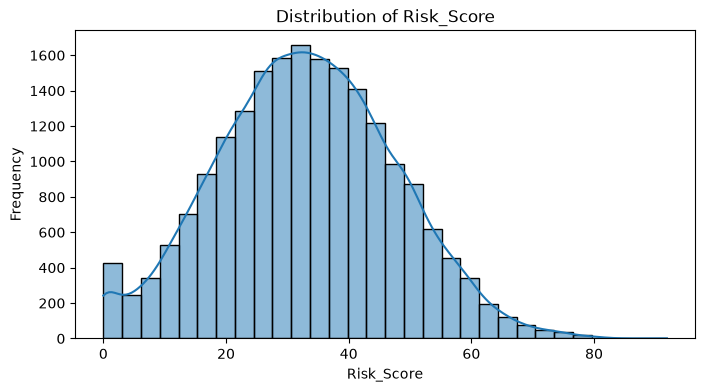

In [20]:
numerical_columns = [
    "Age",
    "Mean_HR",
    "Mean_SpO2",
    "Mean_BP_Sys",
    "Max_Temp",
    "Mean_RR",
    "Mean_GCS",
    "Risk_Score"
]

for col in numerical_columns:
    plt.figure(figsize=(8, 4))

    sns.histplot(data=df, x=col, bins=30, kde=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

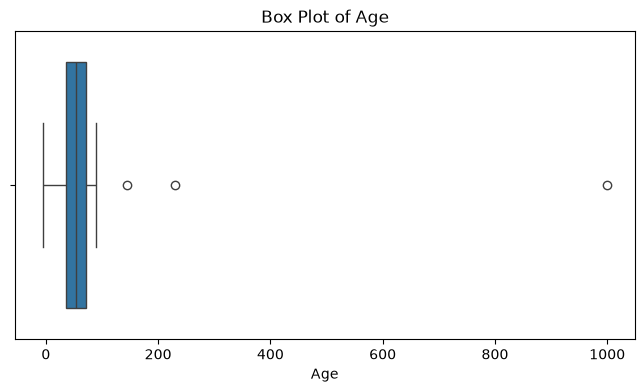

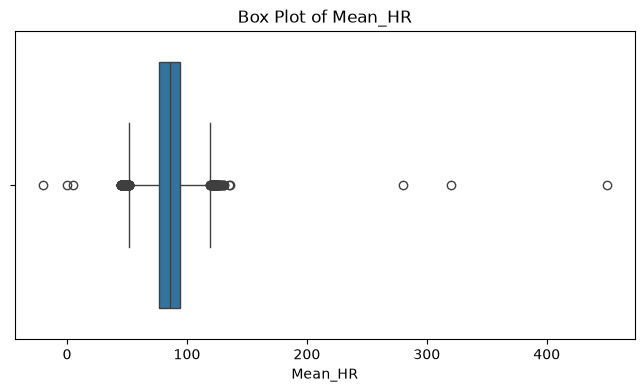

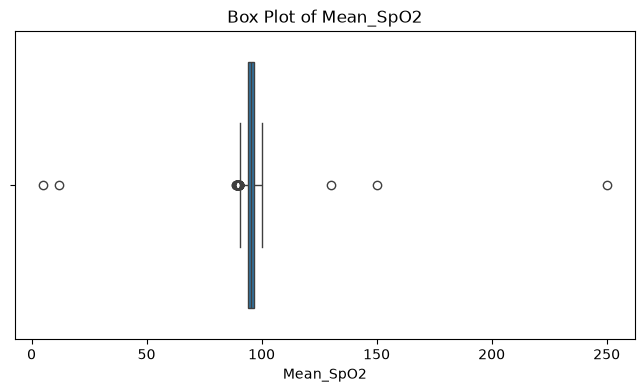

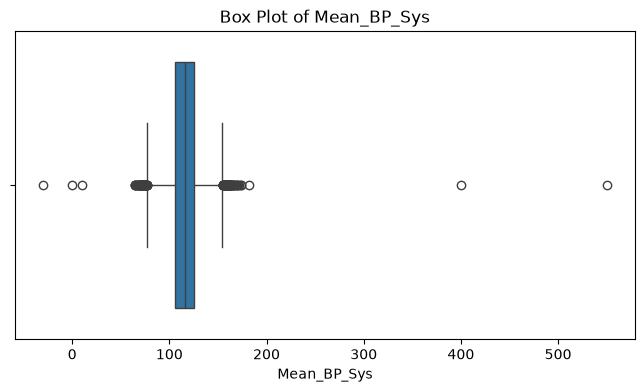

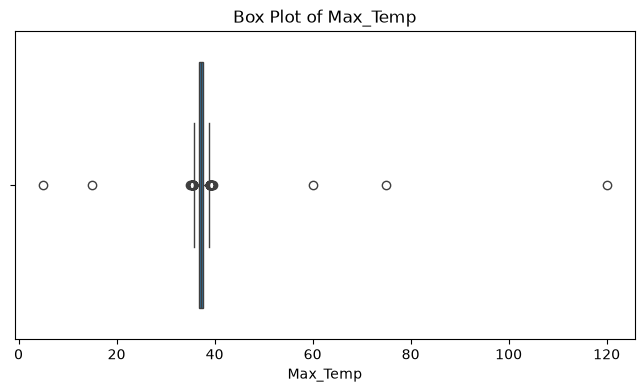

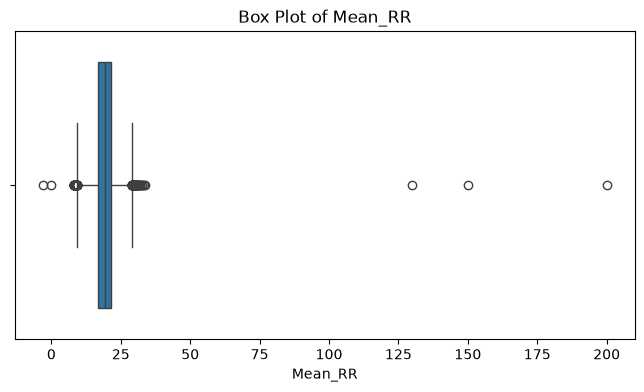

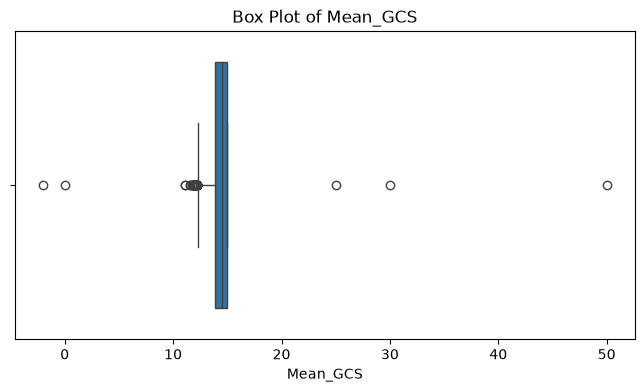

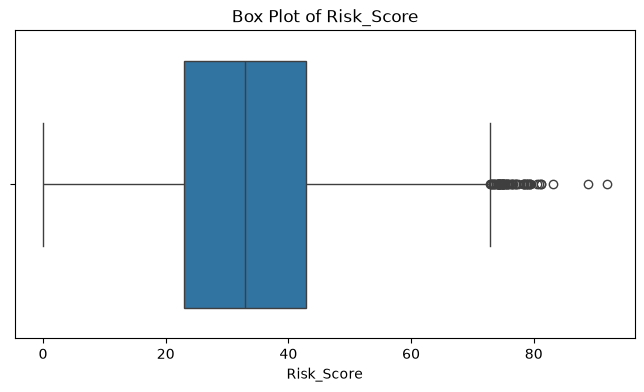

In [21]:
for col in numerical_columns:
    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df, x=col)

    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)

    plt.show()

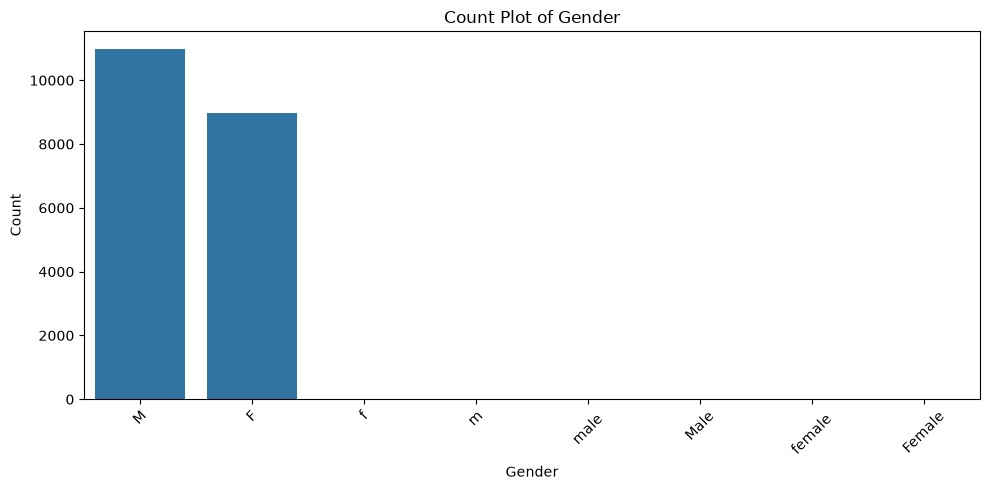

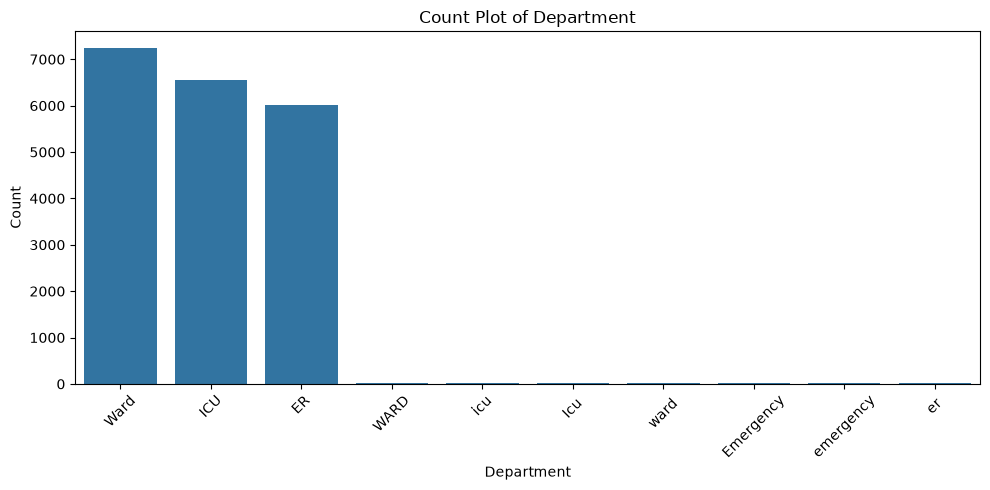

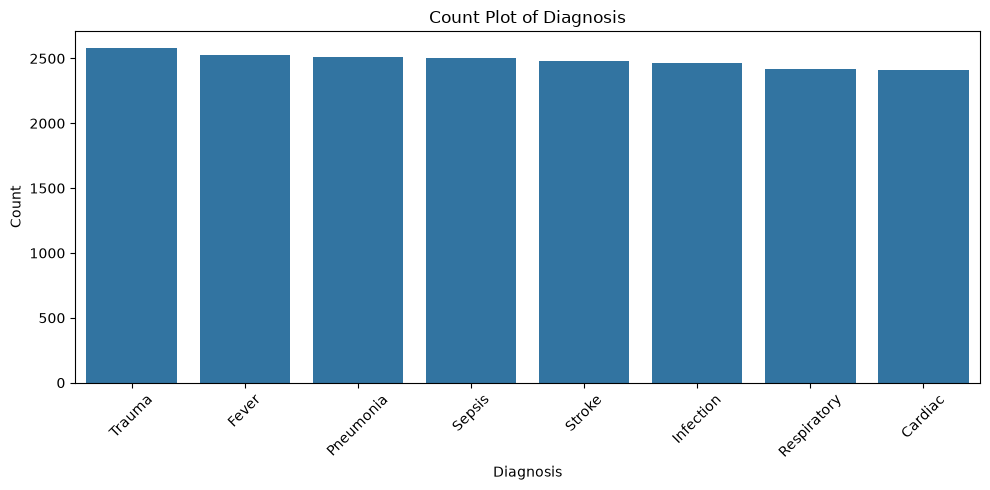

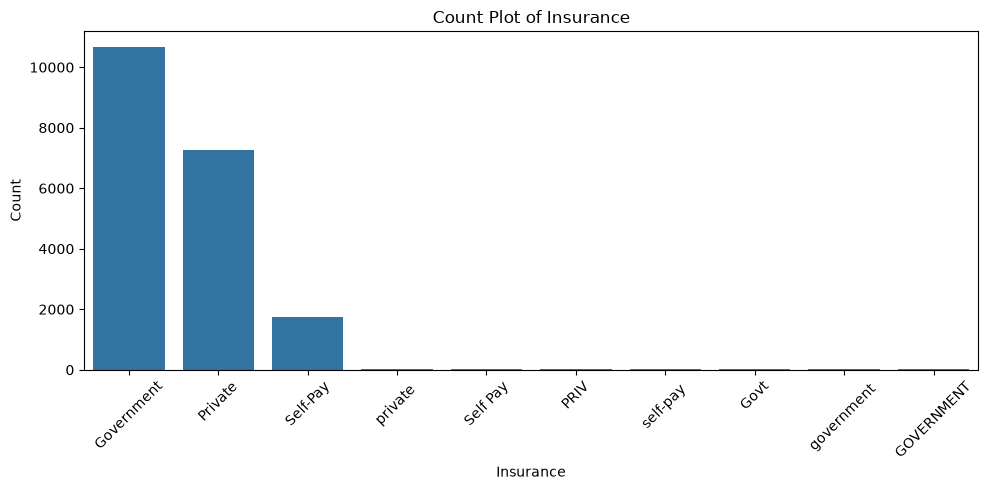

In [22]:
categorical_columns = [
    "Gender",
    "Department",
    "Diagnosis",
    "Insurance"
]

for col in categorical_columns:
    plt.figure(figsize=(10, 5))

    sns.countplot(data=df, x=col, order=df[col].value_counts().index)

    plt.title(f"Count Plot of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

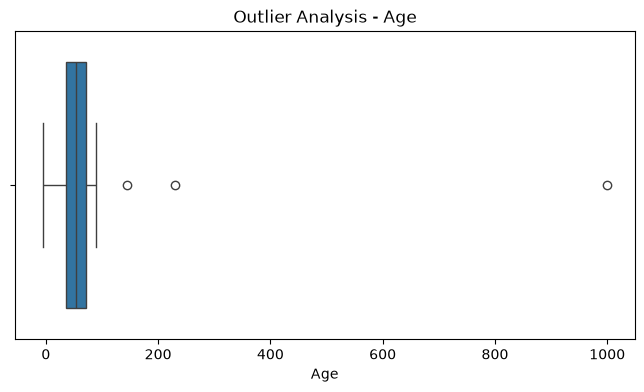

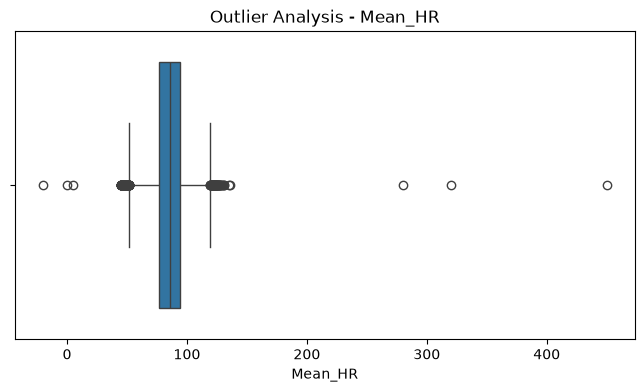

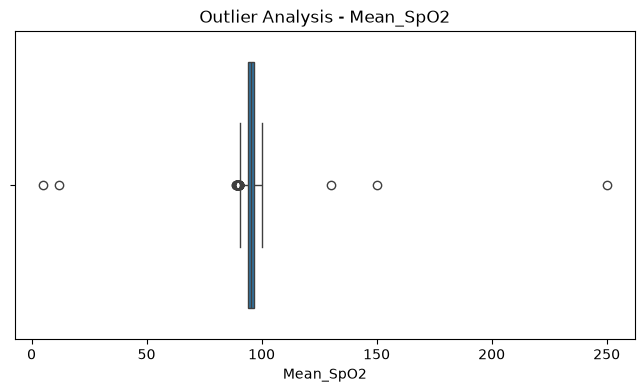

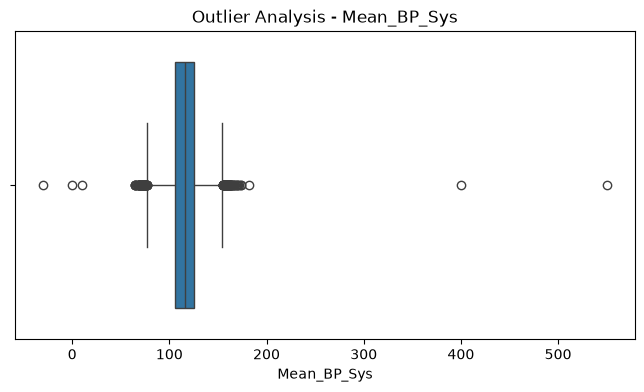

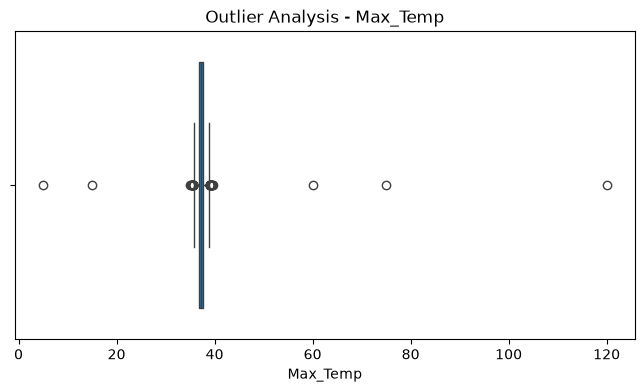

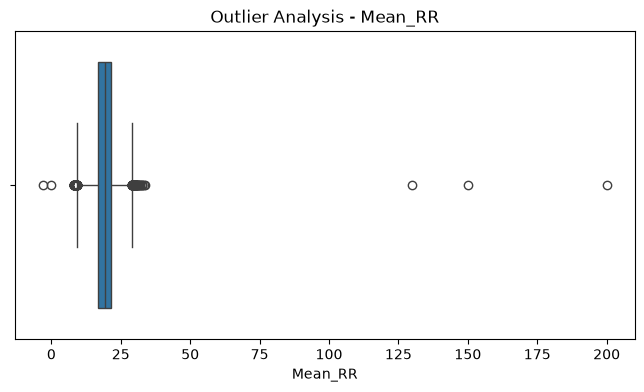

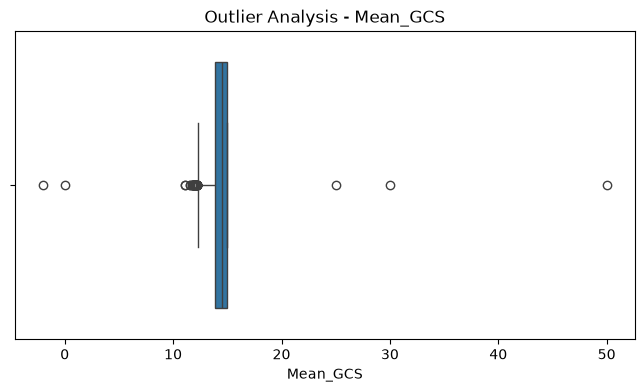

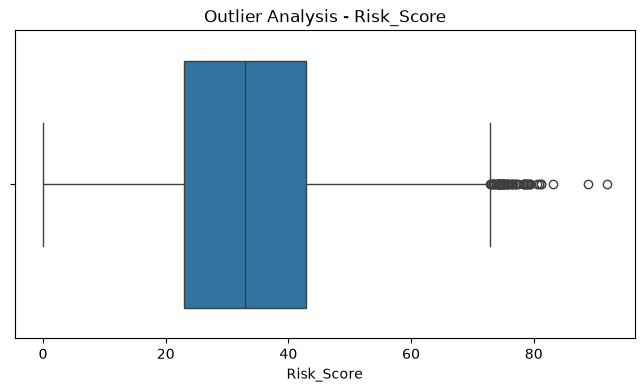

In [23]:
numerical_columns = [
    "Age", "Mean_HR", "Mean_SpO2", "Mean_BP_Sys",
    "Max_Temp", "Mean_RR", "Mean_GCS", "Risk_Score"
]

for col in numerical_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x=col)
    plt.title(f"Outlier Analysis - {col}")
    plt.show()

In [24]:
for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers), "outliers")

Age : 3 outliers
Mean_HR : 124 outliers
Mean_SpO2 : 68 outliers
Mean_BP_Sys : 143 outliers
Max_Temp : 74 outliers
Mean_RR : 151 outliers
Mean_GCS : 75 outliers
Risk_Score : 67 outliers


In [25]:
print(df["Acuity_Bundle"].value_counts())

Acuity_Bundle
ROUTINE_CARE           7379
SEPSIS_HOUR1           4327
CRITICAL_CARE          4110
ENHANCED_MONITORING    2723
RESPIRATORY_SUPPORT    1621
Name: count, dtype: int64


In [26]:
print(df["Acuity_Bundle"].value_counts(normalize=True) * 100)

Acuity_Bundle
ROUTINE_CARE           36.602183
SEPSIS_HOUR1           21.463294
CRITICAL_CARE          20.386905
ENHANCED_MONITORING    13.506944
RESPIRATORY_SUPPORT     8.040675
Name: proportion, dtype: float64


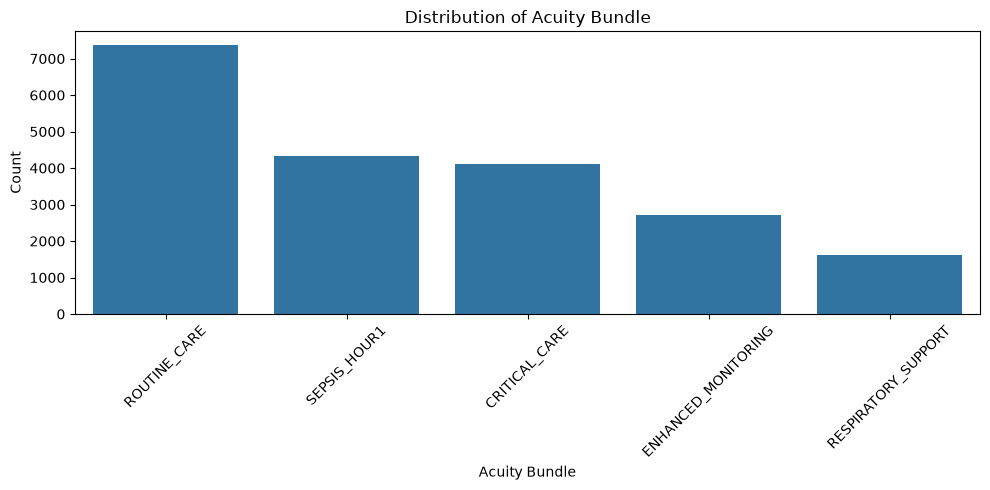

In [27]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="Acuity_Bundle",
              order=df["Acuity_Bundle"].value_counts().index)

plt.title("Distribution of Acuity Bundle")
plt.xlabel("Acuity Bundle")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

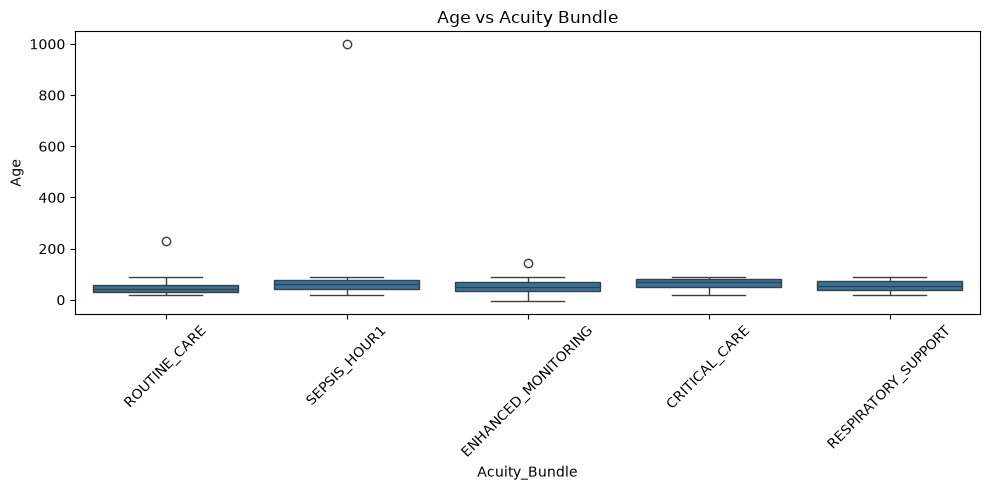

In [28]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="Acuity_Bundle", y="Age")

plt.title("Age vs Acuity Bundle")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

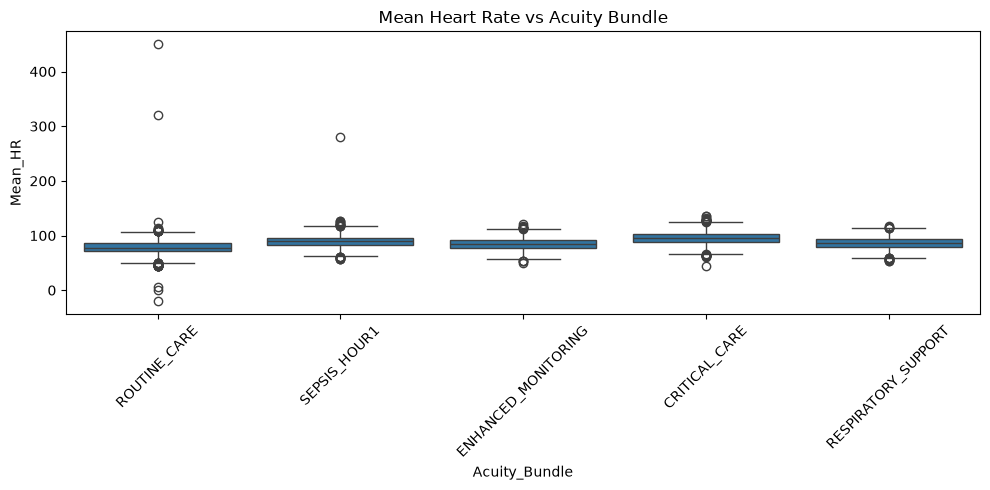

In [29]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="Acuity_Bundle", y="Mean_HR")

plt.title("Mean Heart Rate vs Acuity Bundle")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

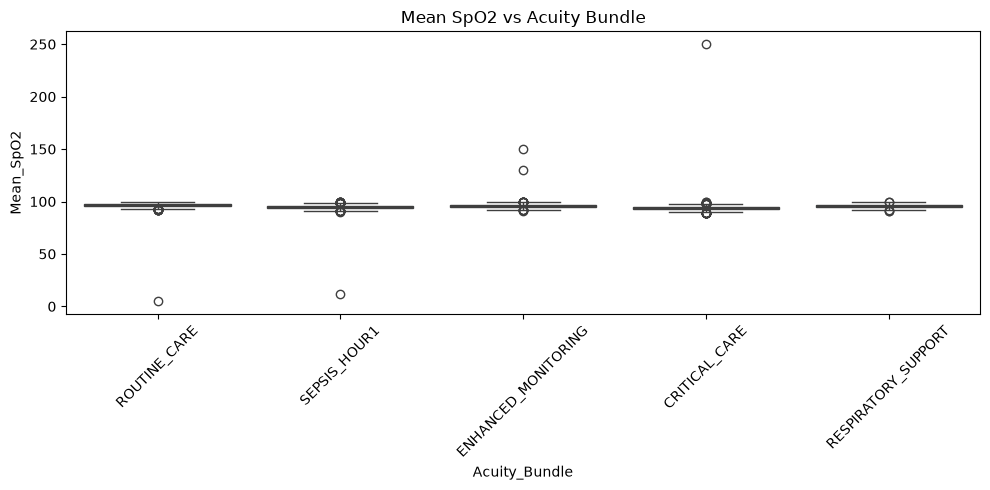

In [30]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="Acuity_Bundle", y="Mean_SpO2")

plt.title("Mean SpO2 vs Acuity Bundle")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

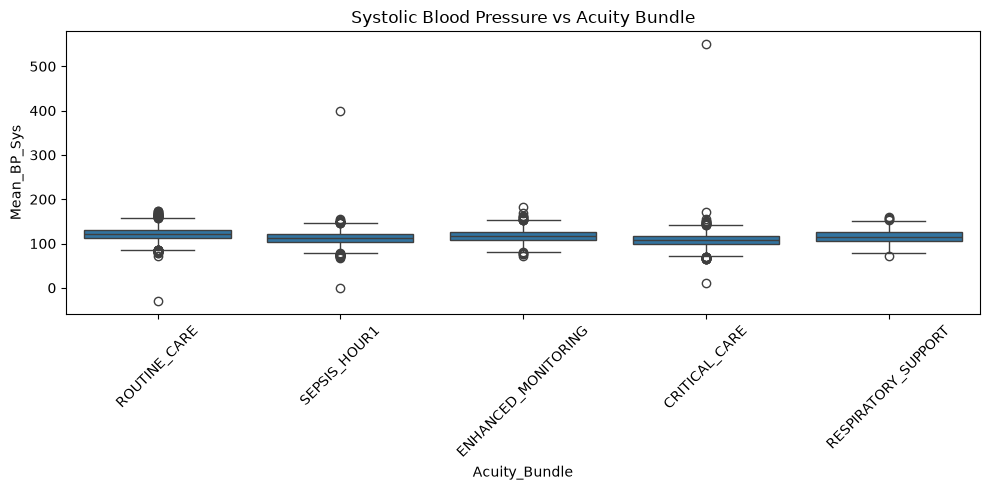

In [31]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="Acuity_Bundle", y="Mean_BP_Sys")

plt.title("Systolic Blood Pressure vs Acuity Bundle")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

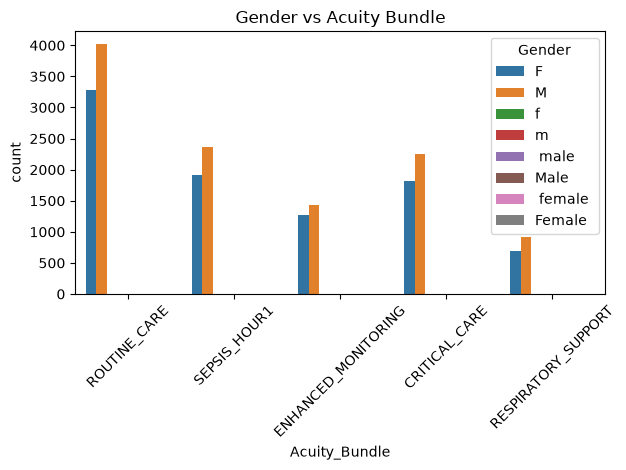

In [32]:
sns.countplot(data=df, x="Acuity_Bundle", hue="Gender")
plt.title("Gender vs Acuity Bundle")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

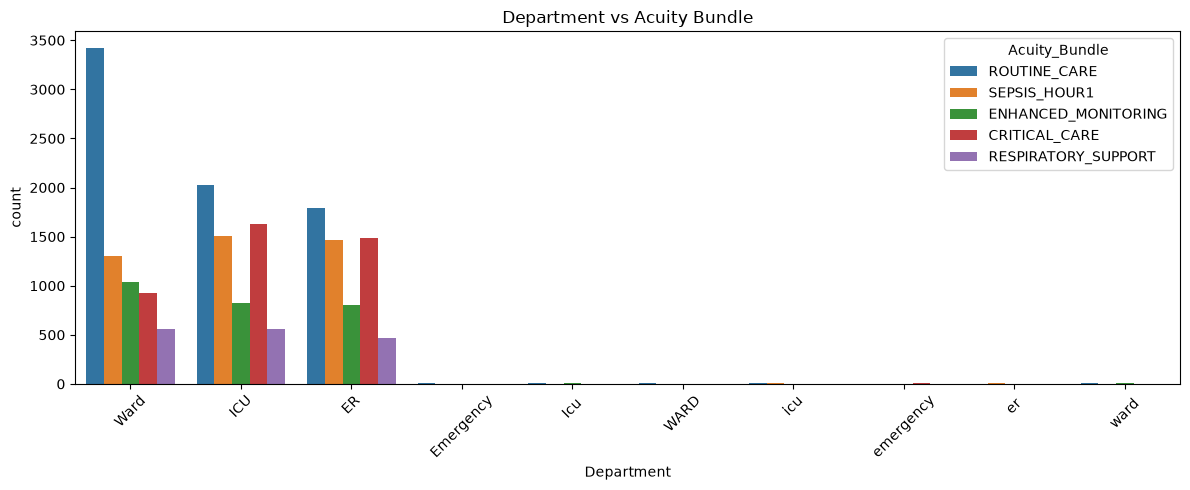

In [33]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="Department", hue="Acuity_Bundle")
plt.title("Department vs Acuity Bundle")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

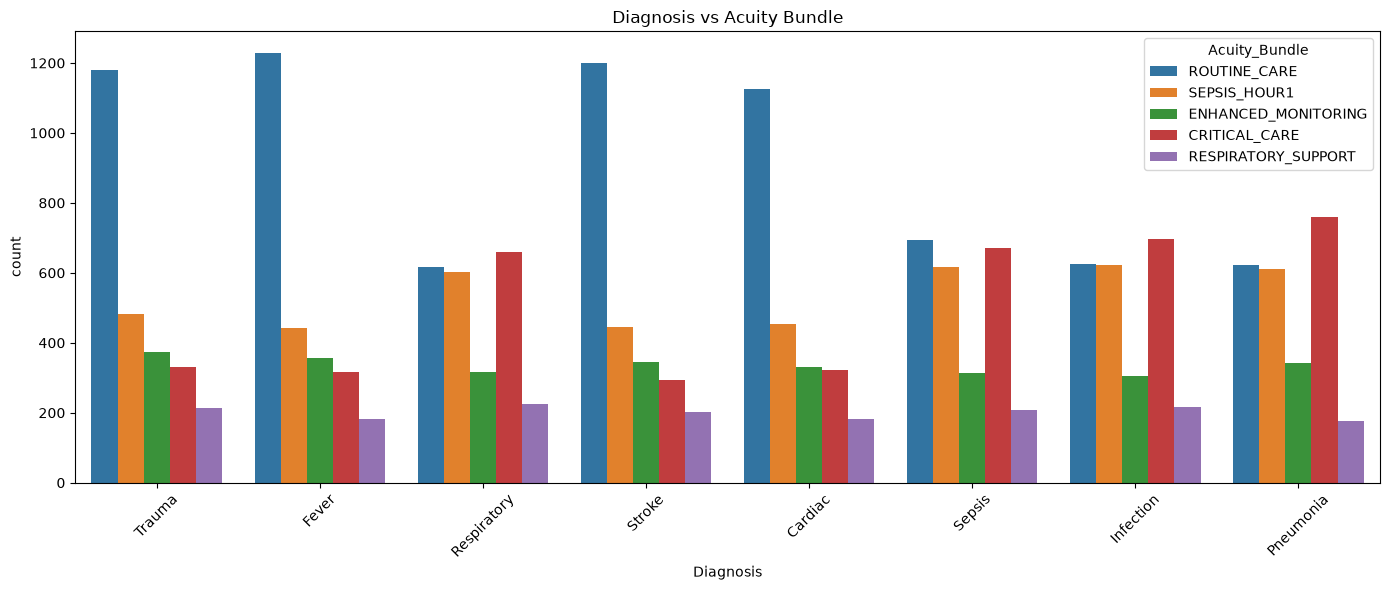

In [34]:
plt.figure(figsize=(14, 6))
sns.countplot(data=df, x="Diagnosis", hue="Acuity_Bundle")
plt.title("Diagnosis vs Acuity Bundle")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

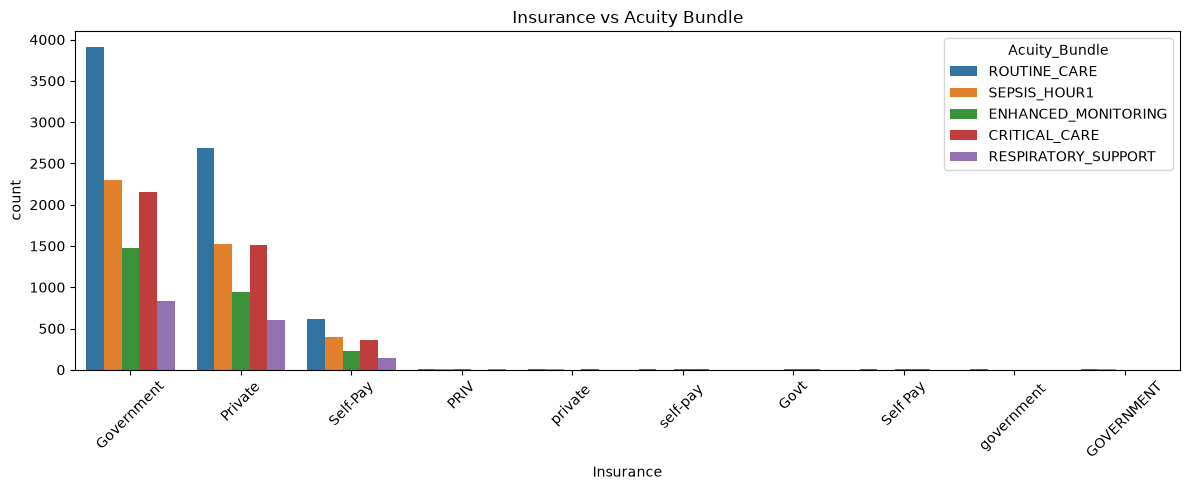

In [35]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="Insurance", hue="Acuity_Bundle")
plt.title("Insurance vs Acuity Bundle")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
numerical_columns = [
    "Age", "Mean_HR", "Mean_SpO2", "Mean_BP_Sys",
    "Max_Temp", "Mean_RR", "Mean_GCS", "Risk_Score"
]

numeric_df = df[numerical_columns]

In [37]:
correlation = numeric_df.corr()

print(correlation)

                  Age   Mean_HR  Mean_SpO2  Mean_BP_Sys  Max_Temp   Mean_RR  \
Age          1.000000  0.202943  -0.189556    -0.159060  0.096884  0.199786   
Mean_HR      0.202943  1.000000  -0.302576    -0.224642  0.141339  0.297776   
Mean_SpO2   -0.189556 -0.302576   1.000000     0.221602 -0.137435 -0.274973   
Mean_BP_Sys -0.159060 -0.224642   0.221602     1.000000 -0.105369 -0.206651   
Max_Temp     0.096884  0.141339  -0.137435    -0.105369  1.000000  0.145517   
Mean_RR      0.199786  0.297776  -0.274973    -0.206651  0.145517  1.000000   
Mean_GCS    -0.159829 -0.256808   0.241905     0.182649 -0.123422 -0.227476   
Risk_Score   0.314475  0.459794  -0.450525    -0.337865  0.230477  0.421912   

             Mean_GCS  Risk_Score  
Age         -0.159829    0.314475  
Mean_HR     -0.256808    0.459794  
Mean_SpO2    0.241905   -0.450525  
Mean_BP_Sys  0.182649   -0.337865  
Max_Temp    -0.123422    0.230477  
Mean_RR     -0.227476    0.421912  
Mean_GCS     1.000000   -0.382819  


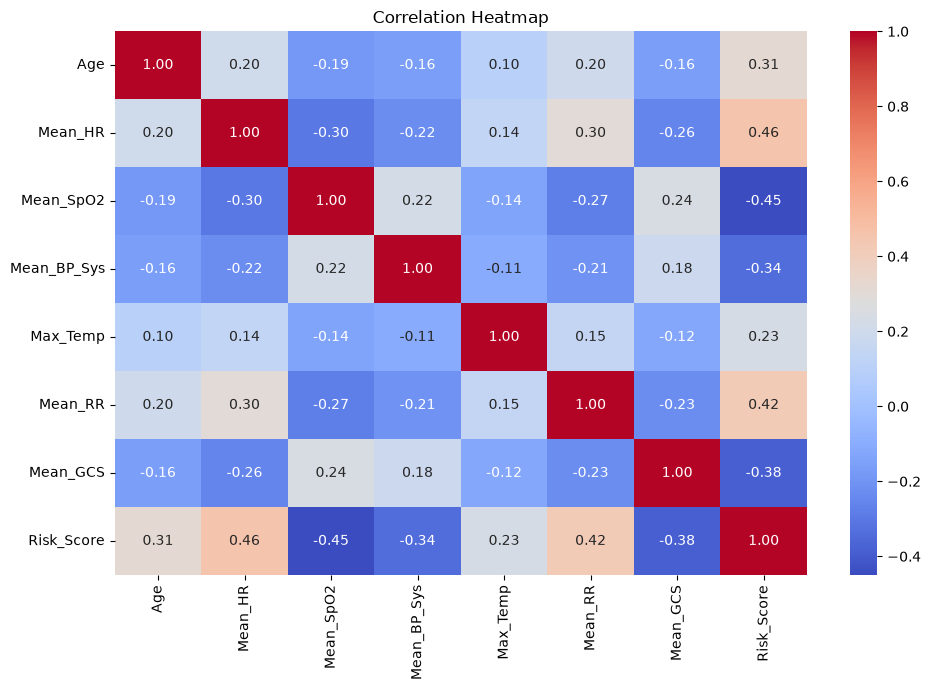

In [38]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [39]:
print(df.columns.tolist())

['Patient_ID', 'Name', 'Age', 'Gender', 'Department', 'Diagnosis', 'ICU_Admitted', 'Assigned_Doctor', 'Assigned_Nurse', 'Blood_Type', 'Comorbidities', 'Insurance', 'Mean_HR', 'Max_HR', 'Std_HR', 'Mean_SpO2', 'Min_SpO2', 'Mean_BP_Sys', 'Min_BP_Sys', 'Max_Temp', 'Mean_RR', 'Max_RR', 'Mean_GCS', 'Min_GCS', 'Hypoxia_Episodes', 'Tachycardia_Episodes', 'Vitals_Count', 'Acuity_Level', 'Risk_Score', 'NEWS2', 'qSOFA', 'SIRS', 'Acuity_Bundle', 'Bundle_Compliance', 'Avg_Bundle_Delay', 'Total_Bundle_Steps', 'LOS', 'Status', 'Discharge_Status', 'ICU_Transfer', 'Readmission', 'Total_Cost_USD', 'Mortality', 'Admission_Date', 'Gender_Enc', 'ICU_Admitted_Enc', 'ICU_Transfer_Enc', 'Readmission_Enc', 'Age_Bucket', 'Dept_Enc', 'Diag_Enc', 'Acuity_Bundle_Enc']
